In [1]:
import pandas as pd

# Data load karein
df = pd.read_csv('gsearch_jobs.csv')

print("Total Rows & Columns:", df.shape)

df.head()

Total Rows & Columns: (61953, 27)


,Unnamed: 0,index,title,company_name,location,via,description,extensions,job_id,thumbnail,...,commute_time,salary_pay,salary_rate,salary_avg,salary_min,salary_max,salary_hourly,salary_yearly,salary_standardized,description_tokens
0,0,0,Data Analyst,Meta,Anywhere,via LinkedIn,In the intersection of compliance and analytic...,"['15 hours ago', '101K–143K a year', 'Work fro...",eyJqb2JfdGl0bGUiOiJEYXRhIEFuYWx5c3QiLCJodGlkb2...,https://encrypted-tbn0.gstatic.com/images?q=tb...,...,NaN,101K–143K,a year,122000.0,101000.0,143000.0,NaN,122000.0,122000.0,"['tableau', 'r', 'python', 'sql']"
1,1,1,Data Analyst,ATC,United States,via LinkedIn,Job Title: Entry Level Business Analyst / Prod...,"['12 hours ago', 'Full-time', 'Health insurance']",eyJqb2JfdGl0bGUiOiJEYXRhIEFuYWx5c3QiLCJodGlkb2...,https://encrypted-tbn0.gstatic.com/images?q=tb...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[]
2,2,2,Aeronautical Data Analyst,"Garmin International, Inc.","Olathe, KS",via Indeed,Overview:\n\nWe are seeking a full-time...\nAe...,"['18 hours ago', 'Full-time']",eyJqb2JfdGl0bGUiOiJBZXJvbmF1dGljYWwgRGF0YSBBbm...,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,['sql']
3,3,3,Data Analyst - Consumer Goods - Contract to Hire,Upwork,Anywhere,via Upwork,Enthusiastic Data Analyst for processing sales...,"['12 hours ago', '15–25 an hour', 'Work from h...",eyJqb2JfdGl0bGUiOiJEYXRhIEFuYWx5c3QgLSBDb25zdW...,NaN,...,NaN,15–25,an hour,20.0,15.0,25.0,20.0,NaN,41600.0,"['powerpoint', 'excel', 'power_bi']"
4,4,4,Data Analyst | Workforce Management,Krispy Kreme,United States,via LinkedIn,Overview of Position\n\nThis position will be ...,"['7 hours ago', '90K–110K a year', 'Contractor']",eyJqb2JfdGl0bGUiOiJEYXRhIEFuYWx5c3QgfCBXb3JrZm...,https://encrypted-tbn0.gstatic.com/images?q=tb...,...,NaN,90K–110K,a year,100000.0,90000.0,110000.0,NaN,100000.0,100000.0,"['powerpoint', 'excel', 'outlook', 'word']"


In [2]:

df.info()

print("\n--- Missing Values Count ---")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 61953 entries, 0 to 61952
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           61953 non-null  int64  
 1   index                61953 non-null  int64  
 2   title                61953 non-null  str    
 3   company_name         61953 non-null  str    
 4   location             61916 non-null  str    
 5   via                  61944 non-null  str    
 6   description          61953 non-null  str    
 7   extensions           61953 non-null  str    
 8   job_id               61953 non-null  str    
 9   thumbnail            38194 non-null  str    
 10  posted_at            61763 non-null  str    
 11  schedule_type        61707 non-null  str    
 12  work_from_home       27980 non-null  object 
 13  salary               10088 non-null  str    
 14  search_term          61953 non-null  str    
 15  date_time            61953 non-null  str    
 1

C:\Users\ayush\AppData\Local\Temp\ipykernel_16772\2911731695.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Count', y='Skill', data=skills_df, palette='viridis')


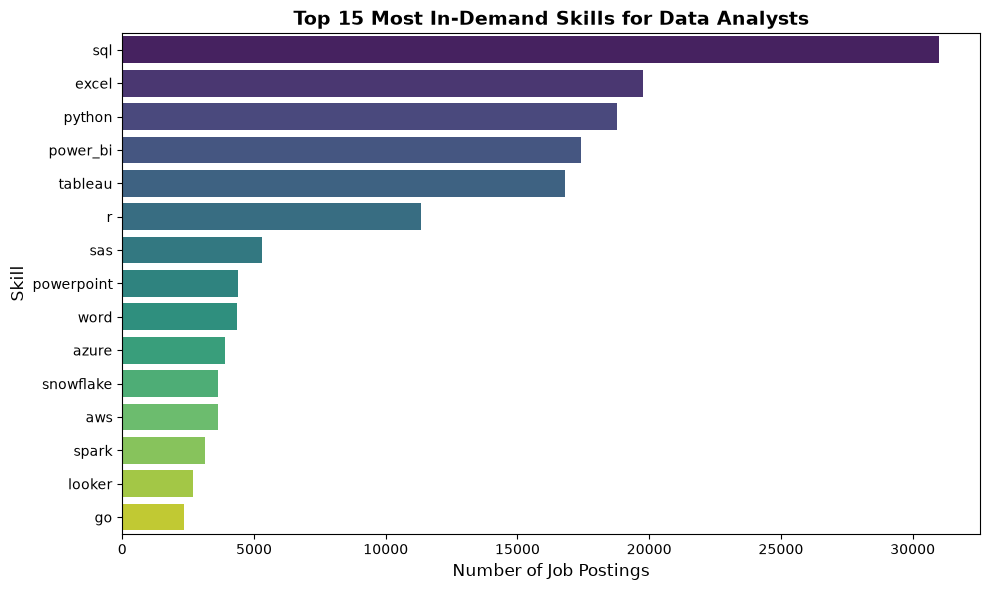

,Skill,Count
0,sql,31006
1,excel,19779
2,python,18793
3,power_bi,17420
4,tableau,16823
5,r,11342
6,sas,5317
7,powerpoint,4411
8,word,4365
9,azure,3887


In [3]:
import ast
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

skills_list = []

for item in df['description_tokens'].dropna():
    try:
        tokens = ast.literal_eval(item)
        if isinstance(tokens, list):
            skills_list.extend([skill.lower().strip() for skill in tokens])
    except:
        continue

skill_counts = Counter(skills_list).most_common(15)
skills_df = pd.DataFrame(skill_counts, columns=['Skill', 'Count'])

# Bar chart plot karein
plt.figure(figsize=(10, 6))
sns.barplot(x='Count', y='Skill', data=skills_df, palette='viridis')
plt.title('Top 15 Most In-Demand Skills for Data Analysts', fontsize=14, fontweight='bold')
plt.xlabel('Number of Job Postings', fontsize=12)
plt.ylabel('Skill', fontsize=12)
plt.tight_layout()
plt.show()

skills_df

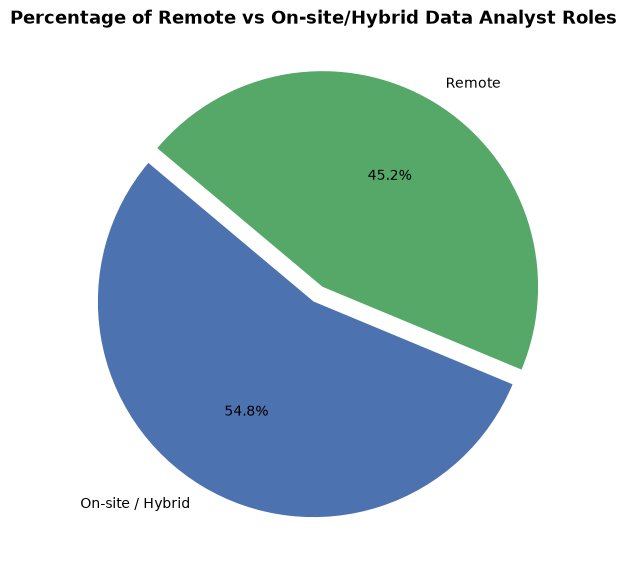

On-site / Hybrid    33973
Remote              27980
Name: count, dtype: int64


In [ ]:

remote_counts = df['work_from_home'].fillna(False).value_counts()
remote_counts.index = ['On-site / Hybrid', 'Remote']

# Pie chart create
plt.figure(figsize=(7, 7))
plt.pie(remote_counts, labels=remote_counts.index, autopct='%1.1f%%', 
        colors=['#4C72B0', '#55A868'], startangle=140, explode=(0, 0.08))
plt.title('Percentage of Remote vs On-site/Hybrid Data Analyst Roles', fontsize=13, fontweight='bold')
plt.show()

# Exact count preview
print(remote_counts)

C:\Users\ayush\AppData\Local\Temp\ipykernel_16772\3157164666.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='median', y='skill', data=top_paid_skills, palette='magma')


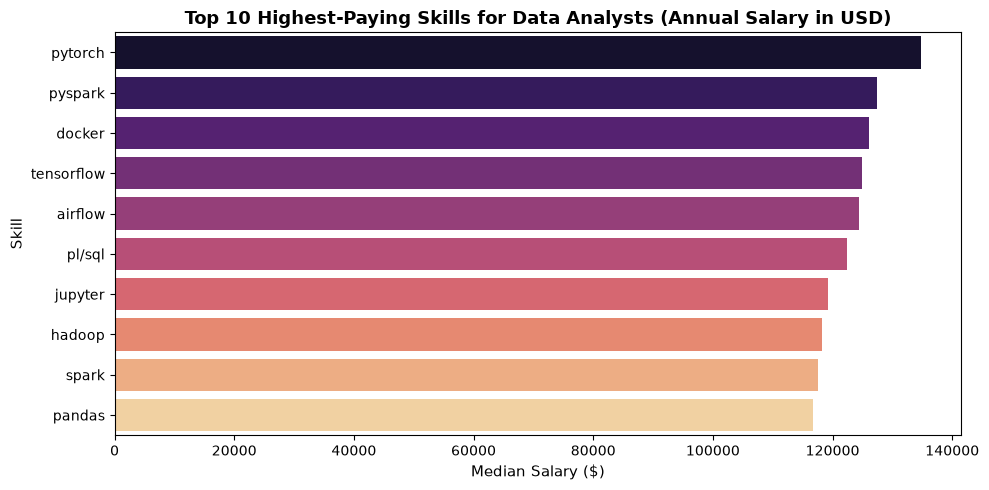

,skill,count,median
77,pytorch,54,134775.0
75,pyspark,57,127500.0
20,docker,56,126025.0
104,tensorflow,60,125000.0
0,airflow,57,124500.0
67,pl/sql,32,122470.5
42,jupyter,39,119257.0
35,hadoop,128,118265.0
94,spark,212,117500.0
64,pandas,121,116700.0


In [ ]:
import ast
salary_df = df.dropna(subset=['salary_yearly', 'description_tokens']).copy()

# Recorded corresponding salary in all skills
skill_salaries = []

for _, row in salary_df.iterrows():
    try:
        tokens = ast.literal_eval(row['description_tokens'])
        sal = row['salary_yearly']
        if isinstance(tokens, list):
            for skill in set(tokens):  # Ek row me ek skill ek hi baar count ho
                skill_salaries.append({'skill': skill.lower().strip(), 'salary': sal})
    except:
        continue

# Making DataFrame 
skill_sal_df = pd.DataFrame(skill_salaries)

# Kam se kam 15-20 postings me aane wali skills ka median salary nikalte hain (taaki outliers na aayein)
skill_stats = skill_sal_df.groupby('skill')['salary'].agg(['count', 'median']).reset_index()
top_paid_skills = skill_stats[skill_stats['count'] >= 20].sort_values(by='median', ascending=False).head(10)

# Bar chart ploting
plt.figure(figsize=(10, 5))
sns.barplot(x='median', y='skill', data=top_paid_skills, palette='magma')
plt.title('Top 10 Highest-Paying Skills for Data Analysts (Annual Salary in USD)', fontsize=13, fontweight='bold')
plt.xlabel('Median Salary ($)', fontsize=11)
plt.ylabel('Skill', fontsize=11)
plt.tight_layout()
plt.show()

top_paid_skills

In [ ]:

skills_df.to_csv('top_in_demand_skills.csv', index=False)
top_paid_skills.to_csv('top_paying_skills.csv', index=False)

print("Processed files saved successfully!")

Processed files saved successfully!
